# Датасет 3. NAB (Numenta Anomaly Benchmark)

**Набор реальных временных рядов с размеченными аномалиями. Берём из него ряды, близкие к нашей теме.**

| | |
|---|---|
| **Источник** | [numenta/NAB](https://github.com/numenta/NAB) |
| **Статья** | Lavin, Ahmad. *Evaluating Real-time Anomaly Detection Algorithms — the Numenta Anomaly Benchmark*, **IEEE ICMLA 2015** |
| **Объём** | 58 рядов, ~365 тыс. точек; я взяла 5 рядов |
| **Лицензия** | AGPL-3.0 (код), данные открыты для исследований |
| **Разметка** | окна аномалий в `labels/combined_windows.json` |

**Какие ряды берём:**

| Файл | Что это | Шаг | Период |
|---|---|---|---|
| `nyc_taxi.csv` | число пассажиров такси в Нью-Йорке | 30 мин | 7 мес. (07.2014–01.2015) |
| `elb_request_count_8c0756.csv` | число запросов к балансировщику нагрузки AWS (ELB) | 5 мин | 2 недели |
| `cpu_utilization_asg_misconfiguration.csv` | CPU кластера AWS с автомасштабированием| 5 мин | 2 мес. |
| `ec2_request_latency_system_failure.csv` | задержка ответа сервера AWS во время сбоя API | 5 мин | 2 недели |
| `Twitter_volume_AMZN.csv` | число твитов про Amazon | 5 мин | 2 мес. |

### Почему именно этии
- **NYC Taxi** — понятный жизненный поток событий с праздниками и погодой
- **ELB request count** — прямой аналог RPS на входе сервиса
- **ASG misconfiguration** - реальный случай, когда  кажется **сломался автоскейлер**
- **Twitter AMZN** - просто интересно было

In [ ]:
# Общие настройки: библиотеки, стиль графиков, функция загрузки
import os, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)

C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
ANOM = '#e34948'
plt.rcParams.update({
    'figure.figsize': (12, 3.6), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'lines.linewidth': 1.2, 'axes.prop_cycle': plt.cycler(color=C), 'axes.axisbelow': True,
    'legend.frameon': False,
})
import matplotlib.dates as mdates

def fmt_dates(ax, fmt='%d.%m'):
    """Компактные подписи дат на оси X."""
    loc = mdates.AutoDateLocator(minticks=5, maxticks=10)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))

def download(url, path, retries=3):
    """Скачивает файл, если его ещё нет; проверяет размер и повторяет при обрыве связи."""
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    if not os.path.exists(path):
        print('Скачиваю', url)
        for attempt in range(1, retries + 1):
            try:
                with urllib.request.urlopen(url, timeout=120) as r, open(path + '.part', 'wb') as f:
                    expected = int(r.headers.get('Content-Length') or 0)
                    while chunk := r.read(1 << 20):
                        f.write(chunk)
                if expected and os.path.getsize(path + '.part') != expected:
                    raise IOError('файл скачался не полностью')
                os.replace(path + '.part', path)
                break
            except Exception as e:
                print(f'  попытка {attempt} не удалась: {e}')
                if attempt == retries: raise
    print(f'{path}: {os.path.getsize(path)/1e6:.1f} МБ')

## 1. Загрузка
Скачиваем 5 CSV-файлов и файл с разметкой. По окнам из разметки каждой точке ставим метку: 1 — внутри аномалии, 0 — норма.

In [ ]:
import json
DATA = 'data/nab'
BASE = 'https://raw.githubusercontent.com/numenta/NAB/master/'
series = {
    'nyc_taxi': 'realKnownCause/nyc_taxi.csv',
    'elb_request_count_8c0756': 'realAWSCloudwatch/elb_request_count_8c0756.csv',
    'cpu_utilization_asg_misconfiguration': 'realKnownCause/cpu_utilization_asg_misconfiguration.csv',
    'ec2_request_latency_system_failure': 'realKnownCause/ec2_request_latency_system_failure.csv',
    'Twitter_volume_AMZN': 'realTweets/Twitter_volume_AMZN.csv',
}
for name, path in series.items():
    download(BASE + 'data/' + path, f'{DATA}/{name}.csv')
download(BASE + 'labels/combined_windows.json', f'{DATA}/combined_windows.json')

labels = json.load(open(f'{DATA}/combined_windows.json'))
data = {}
for name, path in series.items():
    d = pd.read_csv(f'{DATA}/{name}.csv', parse_dates=['timestamp']).set_index('timestamp')['value']
    wins = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in labels[path]]
    lab = pd.Series(0, index=d.index)
    for a, b in wins: lab[(d.index >= a) & (d.index <= b)] = 1
    data[name] = (d, lab, wins)

Скачиваю https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/nyc_taxi.csv
data/nab/nyc_taxi.csv: 0.3 МБ
Скачиваю https://raw.githubusercontent.com/numenta/NAB/master/data/realAWSCloudwatch/elb_request_count_8c0756.csv
data/nab/elb_request_count_8c0756.csv: 0.1 МБ
Скачиваю https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/cpu_utilization_asg_misconfiguration.csv
data/nab/cpu_utilization_asg_misconfiguration.csv: 0.5 МБ
Скачиваю https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/ec2_request_latency_system_failure.csv
data/nab/ec2_request_latency_system_failure.csv: 0.1 МБ
Скачиваю https://raw.githubusercontent.com/numenta/NAB/master/data/realTweets/Twitter_volume_AMZN.csv
data/nab/Twitter_volume_AMZN.csv: 0.4 МБ
Скачиваю https://raw.githubusercontent.com/numenta/NAB/master/labels/combined_windows.json
data/nab/combined_windows.json: 0.0 МБ


## 2. Структура данных
Сводная таблица по всем рядам:

*   шаг почти везде ровный
*   в двух рядах AWS по 8–14 «сбоев» шага (точка пропущена или пришла не
вовремя);
*  аномальных точек около 10% в каждом ряду


In [ ]:
rows = []
for name, (d, lab, wins) in data.items():
    rows.append({'ряд': name, 'точек': len(d), 'начало': d.index.min().date(), 'конец': d.index.max().date(),
                 'шаг': d.index.to_series().diff().mode()[0], 'пропусков': int(d.isna().sum()),
                 'окон аномалий': len(wins), 'доля аномальных точек, %': round(lab.mean() * 100, 1),
                 'среднее': round(d.mean(), 1), 'CV': round(d.std() / d.mean(), 2)})
display(pd.DataFrame(rows))

# Проверка регулярности шага
for name, (d, _, _) in data.items():
    step = d.index.to_series().diff()
    print(f'{name:38s} нерегулярных шагов: {(step != step.mode()[0]).sum() - 1}')

,ряд,точек,начало,конец,шаг,пропусков,окон аномалий,"доля аномальных точек, %",среднее,CV
0,nyc_taxi,10320,2014-07-01,2015-01-31,0 days 00:30:00,0,5,10.0,15137.6,0.46
1,elb_request_count_8c0756,4032,2014-04-10,2014-04-24,0 days 00:05:00,0,2,10.0,61.8,0.92
2,cpu_utilization_asg_misconfiguration,18050,2014-05-14,2014-07-15,0 days 00:05:00,0,1,8.3,38.3,0.41
3,ec2_request_latency_system_failure,4032,2014-03-07,2014-03-21,0 days 00:05:00,0,3,8.6,45.2,0.05
4,Twitter_volume_AMZN,15831,2015-02-26,2015-04-22,0 days 00:05:00,0,4,10.0,53.3,0.57


nyc_taxi                               нерегулярных шагов: 0
elb_request_count_8c0756               нерегулярных шагов: 8
cpu_utilization_asg_misconfiguration   нерегулярных шагов: 0
ec2_request_latency_system_failure     нерегулярных шагов: 14
Twitter_volume_AMZN                    нерегулярных шагов: 0


## 3. NYC Taxi: поток пассажиров и праздники

**График 1:** пассажиры за 7 месяцев. Тонкая линия это значения каждые 30 минут, толстая это среднее за сутки. Красным отмечены 5 аномалий, все это реальные события

**График 2:** тепловая карта «день недели × час». Чем темнее клетка, тем больше пассажиров в среднем:


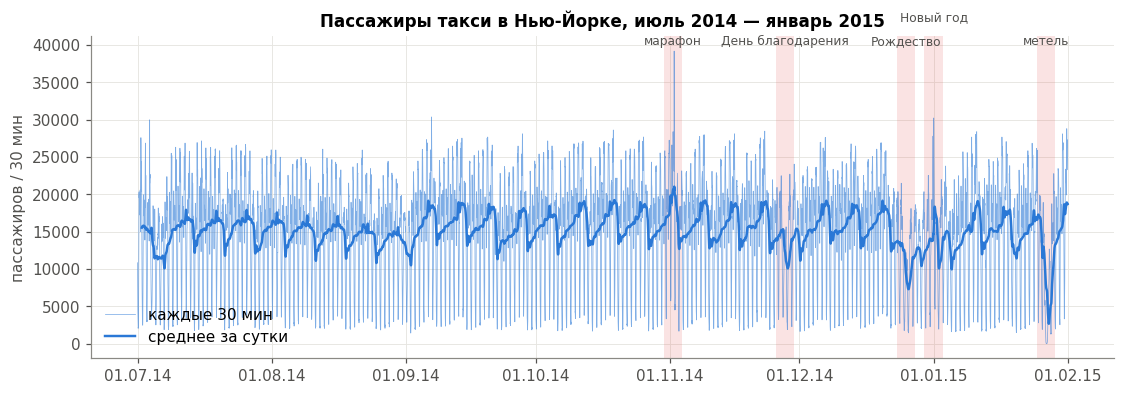

In [ ]:
def shade(ax, wins):
    for a, b in wins:
        ax.axvspan(a, b, color=ANOM, alpha=0.15, lw=0)

taxi, taxi_lab, taxi_wins = data['nyc_taxi']
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(taxi.index, taxi.values, lw=0.5, color=C[0], alpha=0.6, label='каждые 30 мин')
ax.plot(taxi.rolling(48).mean(), lw=1.6, color=C[0], label='среднее за сутки')
shade(ax, taxi_wins)
for i, ((a, b), txt) in enumerate(zip(taxi_wins, ['марафон', 'День благодарения', 'Рождество', 'Новый год', 'метель'])):
    ax.text(a + (b - a) / 2, taxi.max() * (1.02 if i != 3 else 1.10), txt, ha='center', fontsize=8, color='#52514e')
ax.set_title('Пассажиры такси в Нью-Йорке, июль 2014 — январь 2015'); ax.set_ylabel('пассажиров / 30 мин')
ax.legend(loc='lower left'); fmt_dates(ax, '%d.%m.%y'); plt.show()

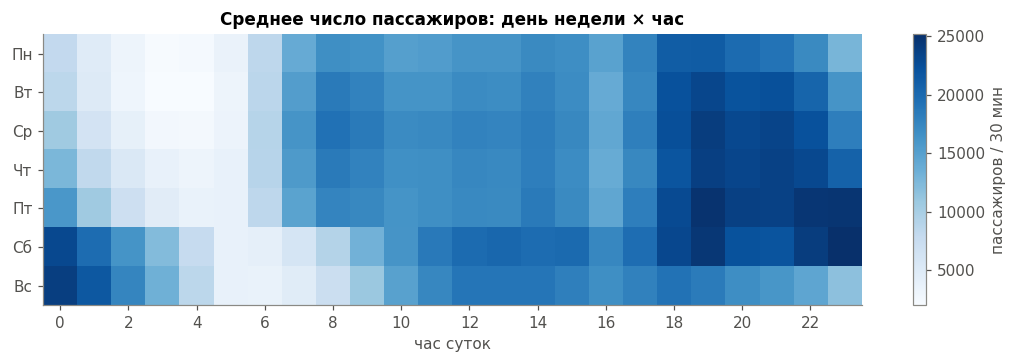

Минимум ночью: 2,031, максимум вечером: 25,193 → разница в 12 раз
Автокорреляция на лаге 30 мин : 0.97
Автокорреляция на лаге 1 час  : 0.90
Автокорреляция на лаге сутки  : 0.80
Автокорреляция на лаге неделя : 0.92


In [ ]:
prof = taxi.groupby([taxi.index.dayofweek, taxi.index.hour]).mean().unstack()
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(prof.values, aspect='auto', cmap='Blues')
ax.set_yticks(range(7)); ax.set_yticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('час суток'); ax.grid(False)
ax.set_title('Среднее число пассажиров: день недели × час'); plt.colorbar(im, ax=ax, label='пассажиров / 30 мин')
plt.show()
print(f'Минимум ночью: {prof.values.min():,.0f}, максимум вечером: {prof.values.max():,.0f} → разница в {prof.values.max()/prof.values.min():.0f} раз')
for lag, name in [(1, '30 мин'), (2, '1 час'), (48, 'сутки'), (336, 'неделя')]:
    print(f'Автокорреляция на лаге {name:7s}: {taxi.autocorr(lag):.2f}')

Отличие от Azure Functions: там суточная автокорреляция была всего 0,12, а здесь 0,80, недельная даже 0,92. У такси очень сильная и правильная сезонность: поток почти точно повторяется каждую неделю. Поэтому аномалии здесь легко заметить: это моменты, когда поток не похож на обычную неделю

## 4. Метрики AWS: запросы, автоскейлер, сбой

Четыре графика друг под другом, красным выделила аномалии:

Запросы к балансировщику (ELB): прямой аналог RPS на входе сервиса. Медиана 48 запросов за 5 минут, пики в 14 раз выше. Аномалии тут необычно сильные всплески

CPU кластера с автоскейлер видны «ступеньки». Нагрузка растёт, CPU доходит до 70–100%, кластер добавляет машину, CPU падает.В конце (красная зона) автоскейлер настроили неправильно: картина ломается, CPU ведёт себя хаотично, а потом падает до ~15%.

Задержка ответа во время сбоя AWS: ровная линия ~45, на сбоях короткие резкие пики

Твиты про Amazon: пример «социальной» нагрузки, всплески связаны с новостями

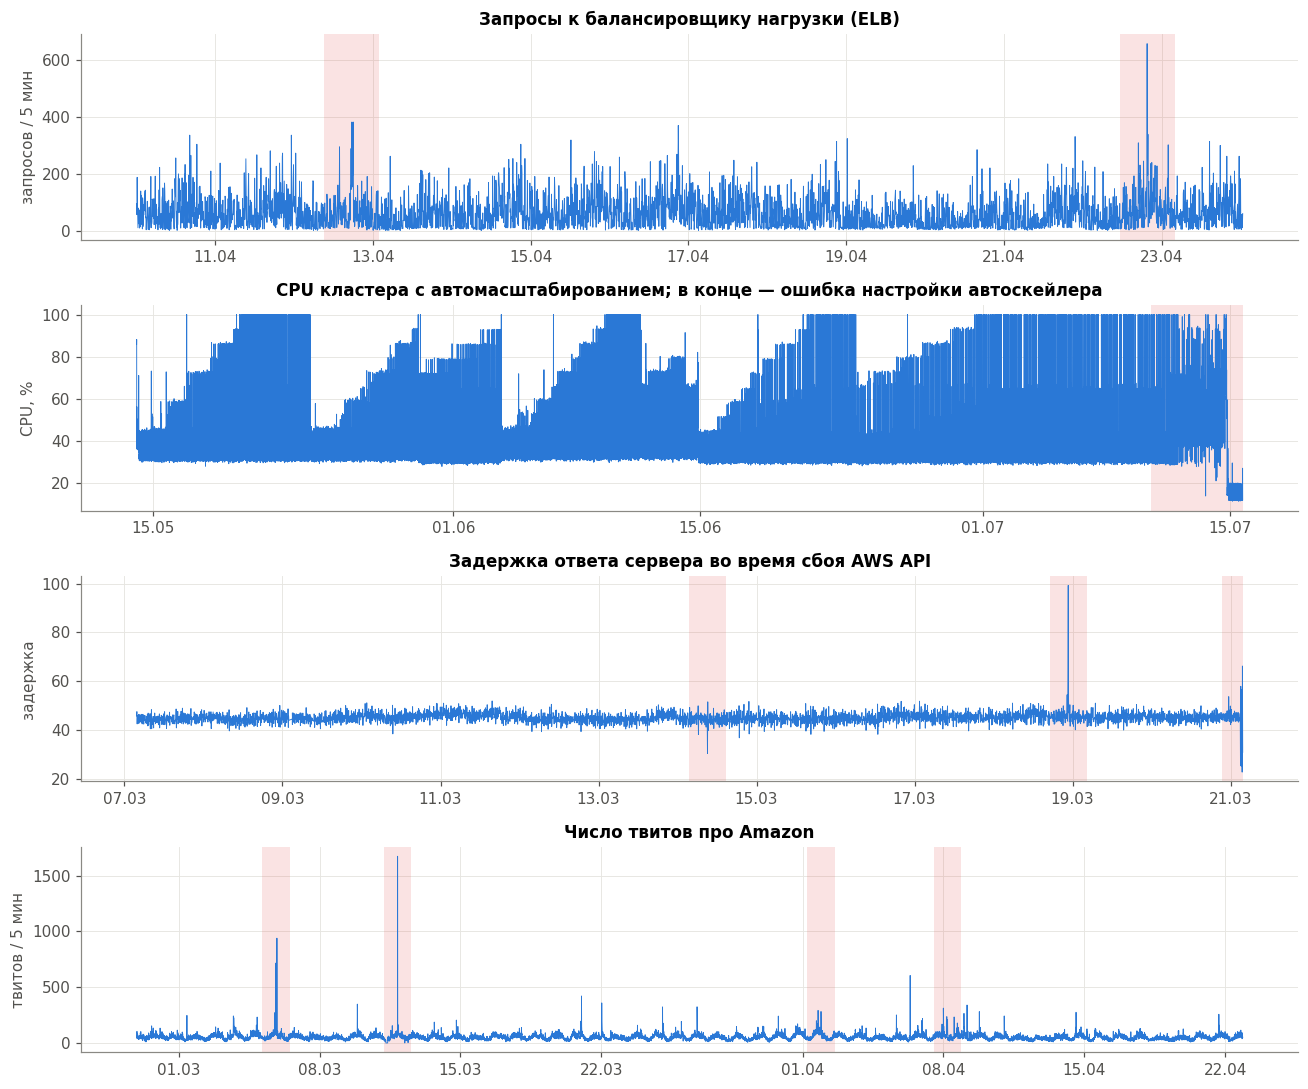

In [ ]:
def shade(ax, wins):
    """Закрашивает окна аномалий красным."""
    for a, b in wins:
        ax.axvspan(a, b, color=ANOM, alpha=0.15, lw=0)

fig, axes = plt.subplots(4, 1, figsize=(12, 10))
titles = {
    'elb_request_count_8c0756': ('Запросы к балансировщику нагрузки (ELB)', 'запросов / 5 мин'),
    'cpu_utilization_asg_misconfiguration': ('CPU кластера с автомасштабированием; в конце какая то беда', 'CPU, %'),
    'ec2_request_latency_system_failure': ('Задержка ответа сервера во время сбоя AWS API', 'задержка'),
    'Twitter_volume_AMZN': ('Число твитов про Amazon', 'твитов / 5 мин'),
}
for ax, (name, (t, yl)) in zip(axes, titles.items()):
    d, lab, wins = data[name]
    ax.plot(d.index, d.values, lw=0.6, color=C[0]); shade(ax, wins)
    ax.set_title(t); ax.set_ylabel(yl); fmt_dates(ax)
plt.tight_layout(); plt.show()

In [ ]:
elb, elb_lab, _ = data['elb_request_count_8c0756']
print(elb.describe(percentiles=[.5, .9, .99]).round(1))
print(f'Пик / медиана = {elb.max()/elb.median():.0f}')
asg, asg_lab, _ = data['cpu_utilization_asg_misconfiguration']
print(f'\nCPU до ошибки автоскейлера: среднее {asg[asg_lab == 0].mean():.1f}%, во время: {asg[asg_lab == 1].mean():.1f}%')

count    4032.0
mean       61.8
std        56.7
min         1.0
50%        48.0
90%       138.0
99%       251.4
max       656.0
Name: value, dtype: float64
Пик / медиана = 14

CPU до ошибки автоскейлера: среднее 37.6%, во время: 45.4%


## 5. Выводы

**Что увидели**
- **Данные чистые:** пропусков нет, шаг почти везде регулярный (в двух рядах AWS по 8–14 сбоев шага).
- **NYC Taxi — эталонный жизненный поток:**
  - очень сильная сезонность: ночью ~2 тыс. пассажиров за 30 минут, вечером до 25 тыс., разница в 12 раз;
  - выражен и суточный, и недельный цикл (автокорреляция 0,8 на сутки и 0,92 на неделю);
  - все 5 аномалий — реальные события (марафон, праздники, метель), они хорошо видны на графике как провалы;
  - 7 месяцев данных: есть и осень, и зима, и праздники.
- **ELB request count** — прямой аналог RPS на входе: медиана 48 запросов за 5 минут, пики в 14 раз выше медианы.
- **ASG misconfiguration** — живой пример работы автоскейлера: видны «ступеньки», когда CPU растёт, кластер добавляет машины и CPU падает. В конце ошибка настройки ломает эту картину. Очень наглядно для презентации.


**Минусы**
- Ряды короткие и одномерные: одна метрика на ряд, связи между компонентами нет.
- Окна аномалий широкие и размечены вручную, точное время начала проблемы неизвестно.
- NYC Taxi агрегирован по 30 минутам: для прогноза на 5–15 минут нужны сырые поездки с сайта TLC (там данные за годы, но скачивать придётся отдельно).

